# Model benchmark: vero-llm on OpenShift AI

The app talks to one model that we serve ourselves: Qwen3-8B (FP8) from the OpenShift AI catalog, running on vLLM on the cluster's single NVIDIA L4.
This notebook runs in the workbench next to it and checks what the app depends on: speed, behaviour with several users at once,
tool calling for the agent (max 8 calls in 60 s) and JSON output for the explanations.

In [1]:
import concurrent.futures as cf
import json
import statistics
import time

import matplotlib.pyplot as plt
import pandas as pd
import requests

BASE = "http://vero-llm-predictor.autonomous-cfo.svc.cluster.local:8080/v1"
MODEL = "vero-llm"

models = requests.get(f"{BASE}/models", timeout=10).json()["data"]
pd.DataFrame([{"id": m["id"], "max_model_len": m.get("max_model_len")} for m in models])

,id,max_model_len
0,vero-llm,32768


In [2]:
def chat(messages, max_tokens=200, **extra):
    body = {"model": MODEL, "messages": messages, "max_tokens": max_tokens, "temperature": 0, **extra}
    start = time.perf_counter()
    r = requests.post(f"{BASE}/chat/completions", json=body, timeout=120)
    r.raise_for_status()
    return r.json(), time.perf_counter() - start

## 1. One request

Streamed, so we can see the time to the first token and the generation speed after it.

In [3]:
def stream_stats(prompt, max_tokens=200):
    body = {
        "model": MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "max_tokens": max_tokens,
        "temperature": 0,
        "stream": True,
        "stream_options": {"include_usage": True},
    }
    start = time.perf_counter()
    first = None
    tokens = 0
    with requests.post(f"{BASE}/chat/completions", json=body, stream=True, timeout=120) as r:
        for line in r.iter_lines():
            if not line.startswith(b"data: ") or line == b"data: [DONE]":
                continue
            chunk = json.loads(line[6:])
            if chunk.get("usage"):
                tokens = chunk["usage"]["completion_tokens"]
            choices = chunk.get("choices") or []
            if first is None and choices and choices[0]["delta"].get("content"):
                first = time.perf_counter()
    total = time.perf_counter() - start
    first = first or start
    return {
        "ttft_s": round(first - start, 3),
        "total_s": round(total, 2),
        "tokens": tokens,
        "tok_per_s": round(tokens / max(total - (first - start), 1e-6), 1),
    }


prompts = [
    "Explain to a pizzeria owner in about 120 words why a 90 day cash forecast matters.",
    "In three short sentences, what is an overdraft limit?",
    "Explain what a credit line is to someone who has never used one, in about 100 words.",
]
single = pd.DataFrame([stream_stats(p) for p in prompts])
single

,ttft_s,total_s,tokens,tok_per_s
0,0.053,5.99,160,26.9
1,0.078,1.95,51,27.3
2,0.079,4.34,115,27.0


## 2. Several requests at once

During the demo a few people may use the app at the same time. The same short request is sent 1, 2, 4 and 8 times in parallel.

In [4]:
def one(_):
    resp, seconds = chat(
        [{"role": "user", "content": "In two sentences, why does a small business need a cash buffer?"}],
        max_tokens=80,
    )
    return seconds, resp["usage"]["completion_tokens"]


rows = []
for n in [1, 2, 4, 8]:
    start = time.perf_counter()
    with cf.ThreadPoolExecutor(n) as pool:
        results = list(pool.map(one, range(n)))
    wall = time.perf_counter() - start
    latencies = [s for s, _ in results]
    rows.append({
        "parallel": n,
        "avg_latency_s": round(statistics.mean(latencies), 2),
        "max_latency_s": round(max(latencies), 2),
        "total_tok_per_s": round(sum(t for _, t in results) / wall, 1),
    })
conc = pd.DataFrame(rows)
conc

,parallel,avg_latency_s,max_latency_s,total_tok_per_s
0,1,1.60,1.60,26.3
1,2,1.61,1.61,52.0
2,4,1.47,1.47,103.0
3,8,1.64,1.65,203.9


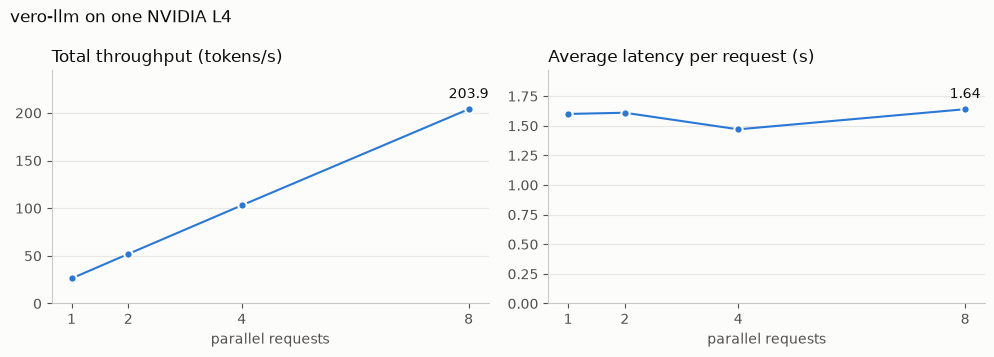

In [5]:
plt.rcParams.update({
    "font.size": 10,
    "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlecolor": "#0b0b0b",
})

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), facecolor="#fcfcfb")
panels = [
    (axes[0], "total_tok_per_s", "Total throughput (tokens/s)"),
    (axes[1], "avg_latency_s", "Average latency per request (s)"),
]
for ax, col, title in panels:
    ax.set_facecolor("#fcfcfb")
    ax.plot(conc["parallel"], conc[col], color="#2a78d6", linewidth=1.5, marker="o", markersize=6,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, solid_capstyle="round", solid_joinstyle="round")
    ax.set_title(title, loc="left")
    ax.set_xlabel("parallel requests")
    ax.set_xticks(conc["parallel"])
    ax.set_ylim(bottom=0, top=conc[col].max() * 1.2)
    ax.grid(axis="y", color="#e8e7e3", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    last = conc.iloc[-1]
    ax.annotate(f"{last[col]:g}", (last["parallel"], last[col]), textcoords="offset points",
                xytext=(0, 8), ha="center", color="#0b0b0b")

fig.suptitle("vero-llm on one NVIDIA L4", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
plt.show()

## 3. Agent tool calling

The June closure scenario from the design doc. The backend tools are mocked with the numbers of the demo scenario,
so only the model is measured. Five runs with temperature 0 (what the app uses) and five with 0.7 as a stress test.

In [6]:
tools = [
    {"type": "function", "function": {
        "name": "get_forecast",
        "description": "Daily cash forecast for the next 91 days, including planned events.",
        "parameters": {"type": "object", "properties": {}}}},
    {"type": "function", "function": {
        "name": "find_reschedule_options",
        "description": "Outgoing payments that could be moved later to stay within the overdraft limit.",
        "parameters": {"type": "object", "properties": {}}}},
    {"type": "function", "function": {
        "name": "size_credit_line",
        "description": "Size a credit line for the shortfall that remains after moving payments.",
        "parameters": {"type": "object",
                       "properties": {"after_moves": {"type": "array", "items": {"type": "string"}}},
                       "required": ["after_moves"]}}},
    {"type": "function", "function": {
        "name": "check_policy",
        "description": "Check which lane an action falls into under the owner's rules.",
        "parameters": {"type": "object", "properties": {"action": {"type": "string"}}, "required": ["action"]}}},
]

answers = {
    "get_forecast": {"limit_eur": -5000, "first_breach": "2025-06-15",
                     "lowest": {"date": "2025-07-03", "eur": -22761}, "driver": "no revenue from 1 to 30 June"},
    "find_reschedule_options": {"options": [{"id": "CHF-06", "what": "transfer to Luigi", "from": "2025-06-15",
                                             "to": "2025-07-30", "first_breach_moves_by_days": 12}],
                                "resolved": False},
    "size_credit_line": {"amount_eur": 20000, "available_from": "2025-06-27", "shortfall_eur": 16081.11},
    "check_policy": {"lane": "DONE_WITHIN_MANDATE", "reason": "transfer below 5000 EUR"},
}

system = ("You are a cash agent for a small business. Investigate with the tools one step at a time, "
          "then propose actions in two or three short sentences. Never invent numbers.")
event = ("Event: the owner plans to close the pizzeria from 1 to 30 June 2025. "
         "Check the cash impact and propose actions.")


def run_agent(temperature):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": event}]
    calls, bad_args, start = [], 0, time.perf_counter()
    for _ in range(10):
        resp, _ = chat(messages, max_tokens=400, temperature=temperature, tools=tools, tool_choice="auto")
        msg = resp["choices"][0]["message"]
        tool_calls = msg.get("tool_calls") or []
        if not tool_calls:
            break
        messages.append({"role": "assistant", "content": msg.get("content") or "", "tool_calls": tool_calls})
        for tc in tool_calls:
            name = tc["function"]["name"]
            try:
                json.loads(tc["function"].get("arguments") or "{}")
            except json.JSONDecodeError:
                bad_args += 1
            calls.append(name)
            result = answers.get(name, {"error": "unknown tool"})
            messages.append({"role": "tool", "tool_call_id": tc["id"], "content": json.dumps(result)})
    seconds = round(time.perf_counter() - start, 1)
    return {
        "temperature": temperature,
        "tool_calls": len(calls),
        "sequence": " > ".join(calls),
        "bad_args": bad_args,
        "seconds": seconds,
        "final_answer": bool(msg.get("content")) and not tool_calls,
        "within_budget": len(calls) <= 8 and seconds <= 60,
        "answer": (msg.get("content") or "").strip(),
    }


runs = pd.DataFrame([run_agent(t) for t in [0.0] * 5 + [0.7] * 5])
runs.drop(columns="answer")

,temperature,tool_calls,sequence,bad_args,seconds,final_answer,within_budget
0,0.0,3,get_forecast > find_reschedule_options > size_...,0,5.8,True,True
1,0.0,3,get_forecast > find_reschedule_options > size_...,0,5.7,True,True
2,0.0,3,get_forecast > find_reschedule_options > size_...,0,5.7,True,True
3,0.0,3,get_forecast > find_reschedule_options > size_...,0,5.7,True,True
4,0.0,3,get_forecast > find_reschedule_options > size_...,0,5.7,True,True
5,0.7,3,get_forecast > find_reschedule_options > size_...,0,4.7,True,True
6,0.7,3,get_forecast > find_reschedule_options > size_...,0,5.6,True,True
7,0.7,3,get_forecast > find_reschedule_options > size_...,0,5.6,True,True
8,0.7,3,get_forecast > find_reschedule_options > size_...,0,4.7,True,True
9,0.7,3,get_forecast > find_reschedule_options > size_...,0,5.1,True,True


In [7]:
runs.groupby("temperature").agg(
    runs=("seconds", "size"),
    within_budget=("within_budget", "sum"),
    avg_seconds=("seconds", "mean"),
    max_seconds=("seconds", "max"),
    avg_tool_calls=("tool_calls", "mean"),
    bad_args=("bad_args", "sum"),
).round(1)

,runs,within_budget,avg_seconds,max_seconds,avg_tool_calls,bad_args
temperature,,,,,,
0.0,5,5,5.7,5.8,3.0,0
0.7,5,5,5.1,5.6,3.0,0


In [8]:
print(runs.loc[0, "answer"])

The cash forecast indicates a significant shortfall due to the closure from 1 to 30 June 2025. Rescheduling the transfer to Luigi from 2025-06-15 to 2025-07-30 reduces the breach risk but still leaves a shortfall. A credit line of €20,000 is recommended to cover the remaining deficit.


## 4. JSON for explanations

The explain step returns JSON with a lane per action. The same actions are sent twice: once with the lane given as a code,
once only described in words. This shows whether the model can be trusted to choose the lane itself.

In [9]:
schema = {
    "type": "object",
    "properties": {
        "headline": {"type": "string"},
        "items": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "title": {"type": "string"},
                    "lane": {"type": "string", "enum": ["DONE_WITHIN_MANDATE", "NEEDS_APPROVAL", "NOT_ALLOWED"]},
                },
                "required": ["title", "lane"],
            },
        },
    },
    "required": ["headline", "items"],
}

cases = [
    [("Postpone Luigi's June transfer to 30 July", "DONE_WITHIN_MANDATE"),
     ("Credit line of 20,000 EUR from 27 June", "NEEDS_APPROVAL")],
    [("Pay the June salaries later", "NOT_ALLOWED"),
     ("Ask the supplier for 30 more days", "NEEDS_APPROVAL")],
    [("Move the quarterly tax prepayment", "NOT_ALLOWED"),
     ("Postpone the equipment lease payment by two weeks", "DONE_WITHIN_MANDATE")],
    [("Open a credit line of 10,000 EUR", "NEEDS_APPROVAL"),
     ("Postpone the July rent by five days", "DONE_WITHIN_MANDATE")],
]
words = {
    "DONE_WITHIN_MANDATE": "already done within the owner's rules",
    "NEEDS_APPROVAL": "needs the owner's approval",
    "NOT_ALLOWED": "not allowed by the owner's rules",
}


def explain(actions, style):
    if style == "codes":
        lines = [f"- {title} (lane: {lane})" for title, lane in actions]
    else:
        lines = [f"- {title}: {words[lane]}" for title, lane in actions]
    prompt = "Write a short headline and one item per action for the owner.\n" + "\n".join(lines)
    resp, seconds = chat(
        [{"role": "user", "content": prompt}],
        max_tokens=300,
        response_format={"type": "json_schema", "json_schema": {"name": "explain", "schema": schema}},
    )
    text = resp["choices"][0]["message"]["content"]
    try:
        obj = json.loads(text)
        got = [item["lane"] for item in obj["items"]]
        return {"style": style, "valid_json": True, "lanes_ok": got == [lane for _, lane in actions],
                "seconds": round(seconds, 1)}
    except (json.JSONDecodeError, KeyError, TypeError):
        return {"style": style, "valid_json": False, "lanes_ok": False, "seconds": round(seconds, 1)}


js = pd.DataFrame([explain(case, style) for style in ["codes", "words"] for case in cases])
js.groupby("style")[["valid_json", "lanes_ok"]].sum()

,valid_json,lanes_ok
style,,
codes,4,4
words,4,3


## Summary

In [10]:
pd.Series({
    "decode speed, one request (tokens/s)": round(single["tok_per_s"].mean(), 1),
    "time to first token (s)": round(single["ttft_s"].mean(), 2),
    "throughput with 8 parallel requests (tokens/s)": conc["total_tok_per_s"].iloc[-1],
    "agent runs within 8 calls / 60 s": f'{int(runs["within_budget"].sum())}/{len(runs)}',
    "slowest agent run (s)": runs["seconds"].max(),
    "tool calls with invalid arguments": int(runs["bad_args"].sum()),
    "valid JSON answers": f'{int(js["valid_json"].sum())}/{len(js)}',
    "lanes right when given as codes": f'{int(js[js["style"] == "codes"]["lanes_ok"].sum())}/{len(cases)}',
    "lanes right when only described": f'{int(js[js["style"] == "words"]["lanes_ok"].sum())}/{len(cases)}',
}, name="result")

decode speed, one request (tokens/s)               27.1
time to first token (s)                            0.07
throughput with 8 parallel requests (tokens/s)    203.9
agent runs within 8 calls / 60 s                  10/10
slowest agent run (s)                               5.8
tool calls with invalid arguments                     0
valid JSON answers                                  8/8
lanes right when given as codes                     4/4
lanes right when only described                     3/4
Name: result, dtype: object

## Conclusion

- One request: first token after about 0.07 s, then about 27 tokens/s. A 150 word explanation takes around 6 s, so it is worth showing progress in the UI.
- Eight requests at once take as long as one (about 1.6 s) and total throughput goes up to about 204 tokens/s. A few people using the demo at the same time is not a problem.
- The agent stays far inside its budget: 10 of 10 runs finished with 3 tool calls in under 6 s, with no invalid arguments, also at temperature 0.7.
- JSON output was always valid. When the lane was only described in words the model picked the wrong lane in 1 of 4 cases, which matches the design where the backend, not the model, decides the lane.